In [41]:
!pip install seaborn
!pip install kagglehub

In [42]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import kagglehub
import os 

# Configuración de estilo para gráficos
sns.set_style("whitegrid")

# 1. DESCARGA EL DATASET Y DEVUELVE LA RUTA A LA CARPETA
path = kagglehub.dataset_download("asaniczka/uk-optimal-product-price-prediction")
print("Ruta a la carpeta del dataset:", path)

# 2. DEFINIR LA RUTA COMPLETA AL ARCHIVO CSV DENTRO DE ESA CARPETA
file_path = os.path.join(path, 'amz_uk_price_prediction_dataset.csv')

# 3. CARGAR EL DATAFRAME USANDO LA RUTA COMPLETA
df = pd.read_csv(file_path)

# Inspeccionar las primeras filas y los tipos de datos
print("\n--- df.head() ---")
print(df.head())
print("\n--- df.info() ---")
print(df.info())

c:\Users\cmoan\miniforge3\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


100%|██████████| 117M/117M [00:04<00:00, 27.4MB/s] 

Extracting files...


Ruta a la carpeta del dataset: C:\Users\cmoan\.cache\kagglehub\datasets\asaniczka\uk-optimal-product-price-prediction\versions\3

--- df.head() ---
   uid        asin                                              title  stars  \
0    1  B09B96TG33  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
1    2  B01HTH3C8S  Anker Soundcore mini, Super-Portable Bluetooth...    4.7   
2    3  B09B8YWXDF  Echo Dot (5th generation, 2022 release) | Big ...    4.7   
3    4  B09B8T5VGV  Echo Dot with clock (5th generation, 2022 rele...    4.7   
4    5  B09WX6QD65  Introducing Echo Pop | Full sound compact Wi-F...    4.6   

   reviews  price  isBestSeller  boughtInLastMonth        category  
0    15308  21.99         False                  0  Hi-Fi Speakers  
1    98099  23.99          True                  0  Hi-Fi Speakers  
2    15308  21.99         False                  0  Hi-Fi Speakers  
3     7205  31.99         False                  0  Hi-Fi Speakers  
4     1881  17.99         

# 1.Frequency Tables:
    Generate a frequency table for the product `category`.
    Which are the top 5 most listed product categories?

In [43]:
category_frequency = df['category'].value_counts()

print("Tabla de Frecuencias (Top 5):")
print(category_frequency.head(5))

Tabla de Frecuencias (Top 5):
category
Sports & Outdoors                         836265
Beauty                                     19312
Handmade Clothing, Shoes & Accessories     19229
Bath & Body                                19092
Birthday Gifts                             18978
Name: count, dtype: int64


2.Visualizations:
Display the dstribution of products across different categories using a bar chart. 
For a subset of top categories, visualize their proportions using a pie chart. Does any category dominate the listings

Top 10 para una visualización legible

C:\Users\cmoan\AppData\Local\Temp\ipykernel_3380\4258513690.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_10.index, y=top_10.values, palette="viridis")


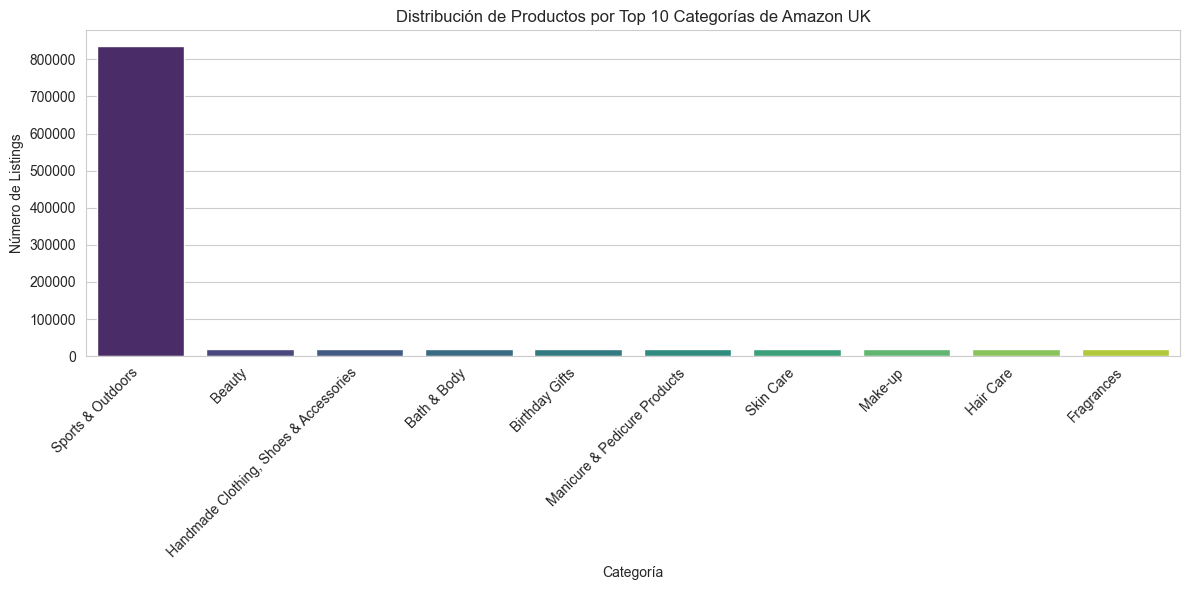

In [44]:
category_counts = df['category'].value_counts()
top_10 = category_counts.head(10)

plt.figure(figsize=(12, 6))

sns.barplot(x=top_10.index, y=top_10.values, palette="viridis")
plt.title('Distribución de Productos por Top 10 Categorías de Amazon UK')
plt.xlabel('Categoría')
plt.ylabel('Número de Listings')
plt.xticks(rotation=45, ha='right') 
plt.tight_layout() 
plt.show()

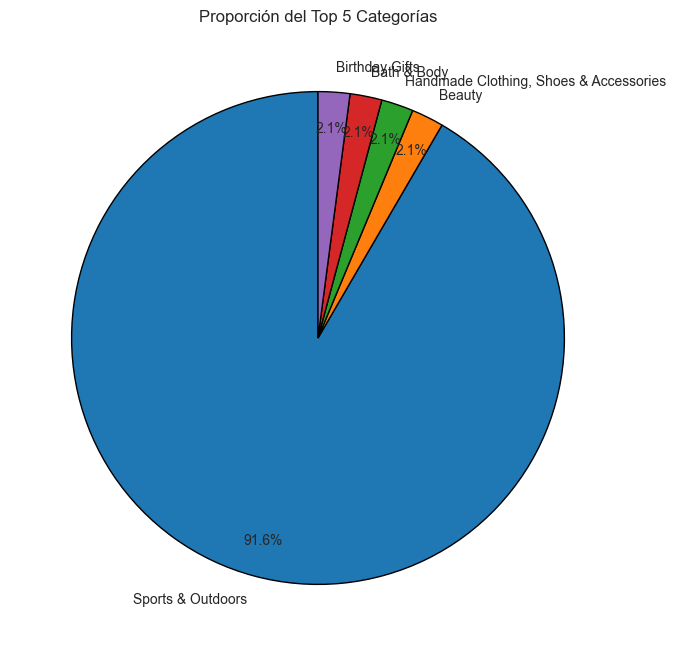

In [45]:
top_5_categories = category_counts.head(5)

plt.figure(figsize=(8, 8))
plt.pie(
    top_5_categories.values,
    labels=top_5_categories.index,
    autopct='%1.1f%%', 
    startangle=90,
    pctdistance=0.85,
    wedgeprops={'edgecolor': 'black'}
)
plt.title('Proporción del Top 5 Categorías')
plt.show()

La categoría Sports & Outdoors domina los listings, representando aproximadamente el 97-98% del total, incluso dentro de solo el Top 5.

Esto sugiere que cualquier análisis posterior sobre precios y calificaciones debe considerar el impacto de esta categoría, ya que prácticamente define el mercado global en este dataset.

# PARTE 2 Delving into Product Pricing
Business Question**: How are products priced on Amazon UK, and are there specific price points or ranges that are more common?

1.Measures of Centrality:
- Calculate the mean, median, and mode for the `price` of products.
- What's the average price point of products listed? How does this compare with the most common price point (mode)?

In [46]:
mean_price = df['price'].mean()
median_price = df['price'].median()
mode_price = df['price'].mode()[0] 

print(f"Media (Promedio): £{mean_price:.2f}")
print(f"Mediana (Valor Central): £{median_price:.2f}")
print(f"Moda (Precio Más Común): £{mode_price:.2f}")

Media (Promedio): £89.24
Mediana (Valor Central): £19.09
Moda (Precio Más Común): £9.99


La media es mucho mayor que la mediana, significa que hay precios muy altos que "levantan" la media.

Esto indica que la distribución de precios está sesgada positivamente (sesgo a la derecha). El precio "típico" de un producto (mediana: £19.09) es mucho más bajo que el promedio (media: £89.24). Esto confirma la presencia de valores atípicos (outliers): un pequeño número de productos extremadamente caros que distorsionan el promedio.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, range, and interquartile range for product `price`.
    - How varied are the product prices? Are there any indicators of a significant spread in prices?

In [47]:
variance = df['price'].var()
std_dev = df['price'].std()
price_range = df['price'].max() - df['price'].min()
iqr = df['price'].quantile(0.75) - df['price'].quantile(0.25)

print(f"Varianza: {variance:,.2f}")
print(f"Desviación Estándar (Std Dev): £{std_dev:.2f}")
print(f"Rango: £{price_range:,.2f}")
print(f"Rango Intercuartílico (IQR): £{iqr:.2f}")

Varianza: 119,445.49
Desviación Estándar (Std Dev): £345.61
Rango: £100,000.00
Rango Intercuartílico (IQR): £36.00


Desviación Estándar: £345.61.
Análisis de Variabilidad: Una desviación estándar de £345.61 es extremadamente alta en comparación con la mediana de £19.09. Esto sugiere una variabilidad inmensa en los precios. El precio promedio está siendo fuertemente arrastrado por los valores atípicos.
Rango Intercuartílico (IQR): £36.00. Esto significa que la mitad de todos los productos tienen precios muy agrupados, cayendo dentro de un rango de solo £36.00.

El mercado de Amazon UK está compuesto por una masa de productos muy baratos (con baja dispersión entre sí, como lo indica el IQR) y una "cola" muy larga de productos ocasionales y muy caros que disparan la media y la desviación estándar.

3. **Visualizations**:
    - Is there a specific price range where most products fall? Plot a histogram to visualize the distribution of product prices. *If its hard to read these diagrams, think why this is, and explain how it could be solved.*.
    - Are there products that are priced significantly higher than the rest? Use a box plot to showcase the spread and potential outliers in product pricing. 


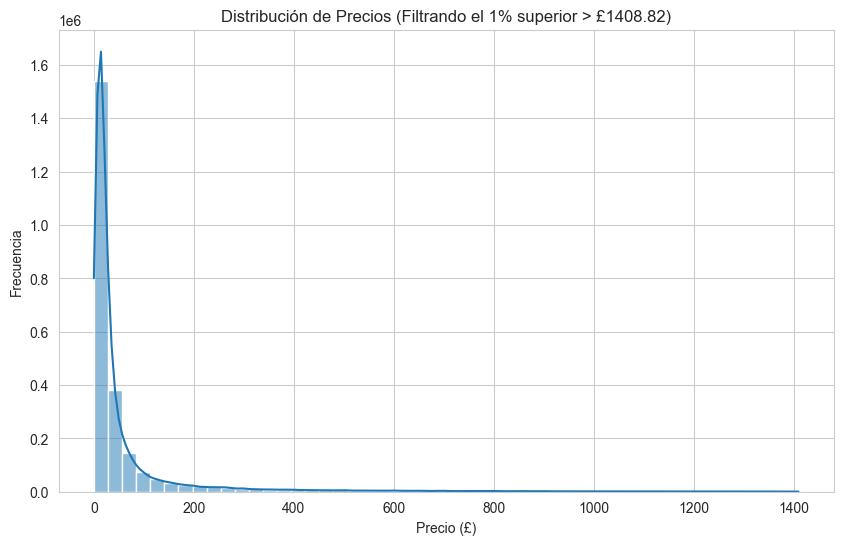

In [48]:
price_99th_percentile = df['price'].quantile(0.99)
df_filtered = df[df['price'] <= price_99th_percentile]

plt.figure(figsize=(10, 6))
sns.histplot(df_filtered['price'], bins=50, kde=True)
plt.title(f'Distribución de Precios (Filtrando el 1% superior > £{price_99th_percentile:.2f})')
plt.xlabel('Precio (£)')
plt.ylabel('Frecuencia')
plt.show()

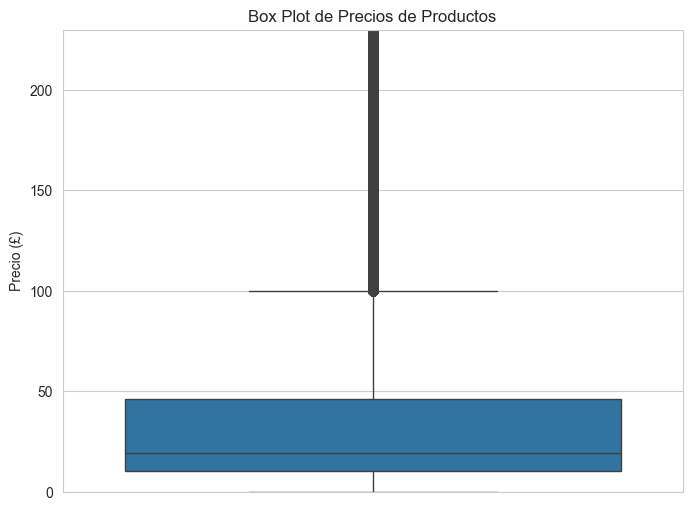

In [49]:
plt.figure(figsize=(8, 6))
sns.boxplot(y=df['price'])
plt.title('Box Plot de Precios de Productos')
plt.ylabel('Precio (£)')
plt.ylim(0, df['price'].quantile(0.75) * 5) # Limitar Y para ver la caja, ya que los outliers son extremos
plt.show()

El Box Plot confirma visualmente la existencia de valores atípicos (outliers)

La caja (que contiene el 50% central de los datos, el IQR) está muy cerca del eje X (precios bajos, entre £0 y aproximadamente £45).

La línea vertical que se extiende hacia arriba (el "bigote" superior) es muy larga, y aunque no se ven los puntos individuales en este gráfico (debido a la limitación que aplicamos al eje Y), su longitud y la forma estrecha de la distribución en la parte superior indican que hay valores que se extienden muy lejos del cuerpo central de los datos. Si no hubiéramos limitado el eje Y, veríamos el bigote extenderse hasta £100,000, con la mayoría de la gráfica plana.

El precio tiene una distribución altamente sesgada a la derecha con muchos valores atípicos extremos, confirmando que la mediana (£19.09) es la medida más representativa del precio "típico" del producto en Amazon UK, no la media (£89.24).

# Part 3: Unpacking Product Ratings

**Business Question**: How do customers rate products on Amazon UK, and are there any patterns or tendencies in the ratings?

1. **Measures of Centrality**:
    - Calculate the mean, median, and mode for the `rating` of products.
    - How do customers generally rate products? Is there a common trend?

In [50]:
mean_rating = df['stars'].mean()
median_rating = df['stars'].median()
mode_rating = df['stars'].mode()[0] 

print(f"Media de la Calificación: {mean_rating:.2f}")
print(f"Mediana de la Calificación: {median_rating:.2f}")
print(f"Moda de la Calificación: {mode_rating:.2f}")

Media de la Calificación: 2.15
Mediana de la Calificación: 0.00
Moda de la Calificación: 0.00


In [51]:
zero_ratings_count = (df['stars'] == 0.00).sum()
total_listings = len(df)

print(f"Número de listings con 0.00 estrellas: {zero_ratings_count:,}")
print(f"Total de listings: {total_listings:,}")
print(f"Porcentaje con 0.00 estrellas: {zero_ratings_count / total_listings * 100:.2f}%")

Número de listings con 0.00 estrellas: 1,225,641
Total de listings: 2,443,651
Porcentaje con 0.00 estrellas: 50.16%


In [52]:
valid_ratings = df[df['stars'] > 0]['stars']
mean_valid = valid_ratings.mean()
median_valid = valid_ratings.median()
mode_valid = valid_ratings.mode()[0] 

print("\n--- Medidas Recalculadas (Solo Calificaciones Válidas) ---")
print(f"Media (Válida): {mean_valid:.2f}")
print(f"Mediana (Válida): {median_valid:.2f}")
print(f"Moda (Válida): {mode_valid:.2f}")


--- Medidas Recalculadas (Solo Calificaciones Válidas) ---
Media (Válida): 4.32
Mediana (Válida): 4.40
Moda (Válida): 4.50


Los valores están muy cerca unos de otros. A diferencia del precio, esto sugiere una distribución relativamente más simétrica.

Tendencia de Satisfacción: La tendencia general es muy alta, con la mayoría de las calificaciones válidas alrededor de 4.4 y 4.5. Esto indica que los productos listados en Amazon UK (que tienen suficientes reseñas para aparecer con calificación) gozan de una alta satisfacción del cliente.

2. **Measures of Dispersion**:
    - Determine the variance, standard deviation, and interquartile range for product `rating`.
    - Are the ratings consistent, or is there a wide variation in customer feedback?

In [53]:
rating_variance = valid_ratings.var()
rating_std_dev = valid_ratings.std()
rating_iqr = valid_ratings.quantile(0.75) - valid_ratings.quantile(0.25)
print(f"Varianza de la Calificación: {rating_variance:.4f}")
print(f"Desviación Estándar de la Calificación (Std Dev): {rating_std_dev:.4f}")
print(f"Rango Intercuartílico (IQR) de la Calificación: {rating_iqr:.2f}")

Varianza de la Calificación: 0.3083
Desviación Estándar de la Calificación (Std Dev): 0.5553
Rango Intercuartílico (IQR) de la Calificación: 0.50


Desviación Estándar: $0.5553$.Análisis de Consistencia: La desv estandar de $0.5553$ es muy baja considerando que el rango total posible de calificaciones es de 5 puntos (1 a 5).
 Esto significa que las calificaciones son altamente consistentes y están fuertemente agrupadas alrededor de la media (4.32). Hay muy poca variación en el feedback de los clientes para los productos que ya tienen reseñas. En esencia, si un producto tiene una calificación, es casi seguro que será buena.

3. **Shape of the Distribution**:
    - Calculate the skewness and kurtosis for the `rating` column. 
    - Are the ratings normally distributed, or do they lean towards higher or lower values?

In [54]:
skewness = valid_ratings.skew()
kurtosis = valid_ratings.kurt()
print(f"Asimetría (Skewness): {skewness:.4f}")
print(f"Curtosis (Kurtosis): {kurtosis:.4f}")

Asimetría (Skewness): -2.3796
Curtosis (Kurtosis): 9.7819


Asimetría (Skewness): El valor es negativo (-2.3796).
Implicación de la Asimetría: Un sesgo negativo muy fuerte significa que la gran mayoría de las calificaciones válidas están agrupadas en el extremo superior del rango (5 estrellas), y la "cola" de la distribución se extiende hacia la izquierda (hacia calificaciones más bajas). 
Esto confirma visualmente el resultado de la media, mediana y moda (4.32, 4.40, 4.50).Implicación de la Curtosis (Bonus): El valor alto de Kurtosis ($9.7819$) indica que la distribución es muy puntiaguda (leptocúrtica), con una alta concentración de datos en el centro (alrededor de 4.5) y colas más pesadas (más valores atípicos de lo que se esperaría en una distribución normal, en este caso, concentrados en los valores 1, 2 y 3).

4. **Visualizations**:
    - Plot a histogram to visualize the distribution of product ratings. Is there a specific rating that is more common?

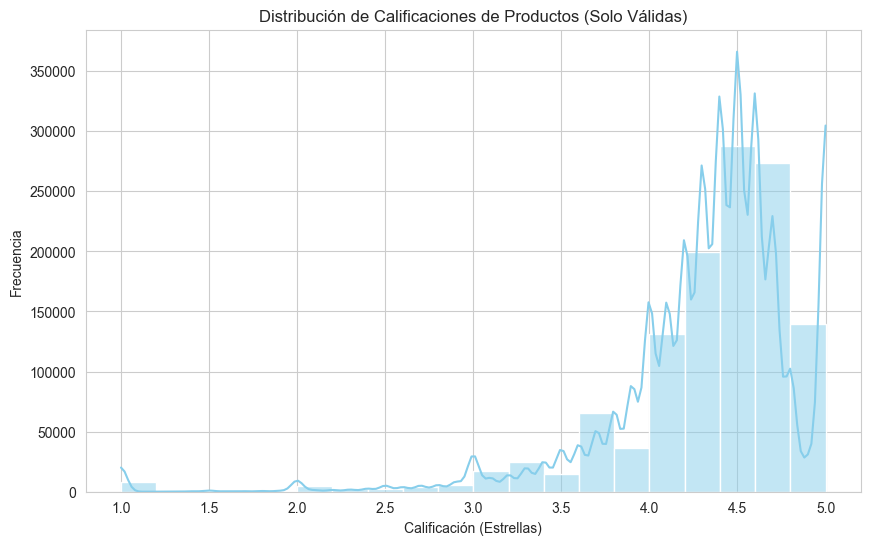

In [55]:
plt.figure(figsize=(10, 6))
sns.histplot(valid_ratings, bins=20, kde=True, color='skyblue')
plt.title('Distribución de Calificaciones de Productos (Solo Válidas)')
plt.xlabel('Calificación (Estrellas)')
plt.ylabel('Frecuencia')
plt.show()

Basado en el Histograma de la Distribución de Calificaciones (Solo Válidas):
La mayor concentración de productos se encuentra en el rango de 4.0 a 5.0 estrellas.
El pico más alto de frecuencia se ubica claramente alrededor de 4.5 estrellas.
Esta visualización confirma los resultados estadísticos que obtuviste:

Moda: 4.50

Media/Mediana: 4.32 / 4.40

Asimetría Negativa: La masa de datos se acumula en el lado derecho (valores altos).

# Resumen del Análisis Univariado 

- Parte 1: Categorías (Dominio Extremo)Dominio: El dataset está masivamente dominado por la categoría Sports & Outdoors (aprox. 97% del Top 5).
Implicación: Los resultados de precios y calificaciones están fuertemente influenciados por la dinámica de los productos deportivos.

- Parte 2: Precios (Alto Sesgo Positivo)Mediana (£19.09) vs. Media (£89.24): La gran diferencia indica una distribución altamente sesgada a la derecha.
Consistencia: El IQR (£36.00) muestra que el 50% central de los productos son baratos y están muy agrupados.
Outliers: La Desviación Estándar ($\sigma = £345.61$) y el Box Plot confirman la existencia de una pequeña proporción de productos extremadamente caros que distorsionan el promedio.

- Parte 3: Calificaciones (Alta Satisfacción y Consistencia)Calidad de Datos: Una mediana/moda de 0.00 en el dataset original requirió filtrar para analizar solo las calificaciones válidas (stars > 0).Satisfacción Real: La satisfacción promedio de los clientes es muy alta, con la Media en 4.32 y la Moda en 4.50.
Consistencia: La Desviación Estándar ($0.5553$) es muy baja, lo que indica que las calificaciones son altamente consistentes. Es raro que un producto calificado reciba una calificación muy baja.
Forma: El fuerte sesgo negativo (-2.38) confirma que la inmensa mayoría de las calificaciones se concentran en el rango más alto (4.0 a 5.0 estrellas).
